# ☕ Análise Exploratória — Café e Qualidade do Sono

Objetivo: entender o perfil dos clientes e como o consumo de café se relaciona com sono, estresse e saúde.

## 1. Carregar o dataset e conhecer os dados

**Importar as bibliotecas** — trazemos as ferramentas de análise (pandas) e de gráficos (matplotlib e seaborn).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**Ler o arquivo** — carregamos o CSV numa tabela (`df`) e mostramos as 5 primeiras linhas.

In [2]:
df = pd.read_csv("data/synthetic_coffee_health_10000(in).csv")
df.head()

,ID,Age,Gender,Country,Coffee_Intake,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Health_Issues,Occupation,Smoking,Alcohol_Consumption
0,1,40,Male,Germany,3.5,328.1,7.5,Good,24.9,78,Low,14.5,NaN,Other,0,0
1,2,33,Male,Germany,1.0,94.1,6.2,Good,20.0,67,Low,11.0,NaN,Service,0,0
2,3,42,Male,Brazil,5.3,503.7,5.9,Fair,22.7,59,Medium,11.2,Mild,Office,0,0
3,4,53,Male,Germany,2.6,249.2,7.3,Good,24.7,71,Low,6.6,Mild,Other,0,0
4,5,32,Female,Spain,3.1,298.0,5.3,Fair,24.1,76,Medium,8.5,Mild,Student,0,1


**Dimensões** — quantas linhas (pessoas) e colunas (informações) a base tem.

In [3]:
df.shape

(10000, 16)

**Colunas e tipos de dados** — lista cada coluna, seu tipo (número ou texto) e quantos valores preenchidos ela tem.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       10000 non-null  int64  
 1   Age                      10000 non-null  int64  
 2   Gender                   10000 non-null  str    
 3   Country                  10000 non-null  str    
 4   Coffee_Intake            10000 non-null  float64
 5   Caffeine_mg              10000 non-null  float64
 6   Sleep_Hours              10000 non-null  float64
 7   Sleep_Quality            10000 non-null  str    
 8   BMI                      10000 non-null  float64
 9   Heart_Rate               10000 non-null  int64  
 10  Stress_Level             10000 non-null  str    
 11  Physical_Activity_Hours  10000 non-null  float64
 12  Health_Issues            4059 non-null   str    
 13  Occupation               10000 non-null  str    
 14  Smoking                  10000 non

**Valores nulos** — conta quantos valores estão faltando em cada coluna.

In [5]:
df.isnull().sum()

ID                            0
Age                           0
Gender                        0
Country                       0
Coffee_Intake                 0
Caffeine_mg                   0
Sleep_Hours                   0
Sleep_Quality                 0
BMI                           0
Heart_Rate                    0
Stress_Level                  0
Physical_Activity_Hours       0
Health_Issues              5941
Occupation                    0
Smoking                       0
Alcohol_Consumption           0
dtype: int64

A coluna `Health_Issues` parece ter 5.941 nulos, mas na verdade são pessoas **sem problemas de saúde** (categoria `"None"`),
que o pandas lê como vazio. Então substituímos esses vazios por `"None"`.

In [6]:
df["Health_Issues"] = df["Health_Issues"].fillna("None")
df.isnull().sum().sum()

np.int64(0)

**Duplicados** — conta quantas linhas estão repetidas.

In [7]:
df.duplicated().sum()

np.int64(0)

**Estatísticas descritivas** — mostra média, mínimo, máximo e quartis de cada coluna numérica.

In [8]:
df.describe()

,ID,Age,Coffee_Intake,Caffeine_mg,Sleep_Hours,BMI,Heart_Rate,Physical_Activity_Hours,Smoking,Alcohol_Consumption
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.00000,10000.000000
mean,5000.50000,34.949100,2.509230,238.411010,6.636220,23.986860,70.617800,7.48704,0.20040,0.300700
std,2886.89568,11.160939,1.450248,137.748815,1.222055,3.906411,9.822951,4.31518,0.40032,0.458585
min,1.00000,18.000000,0.000000,0.000000,3.000000,15.000000,50.000000,0.00000,0.00000,0.000000
25%,2500.75000,26.000000,1.500000,138.750000,5.800000,21.300000,64.000000,3.70000,0.00000,0.000000
50%,5000.50000,34.000000,2.500000,235.400000,6.600000,24.000000,71.000000,7.50000,0.00000,0.000000
75%,7500.25000,43.000000,3.500000,332.025000,7.500000,26.600000,77.000000,11.20000,0.00000,1.000000
max,10000.00000,80.000000,8.200000,780.300000,10.000000,38.200000,109.000000,15.00000,1.00000,1.000000


## 2. Variáveis numéricas

**Histogramas** — mostram como os valores de cada variável se distribuem (onde estão concentrados).

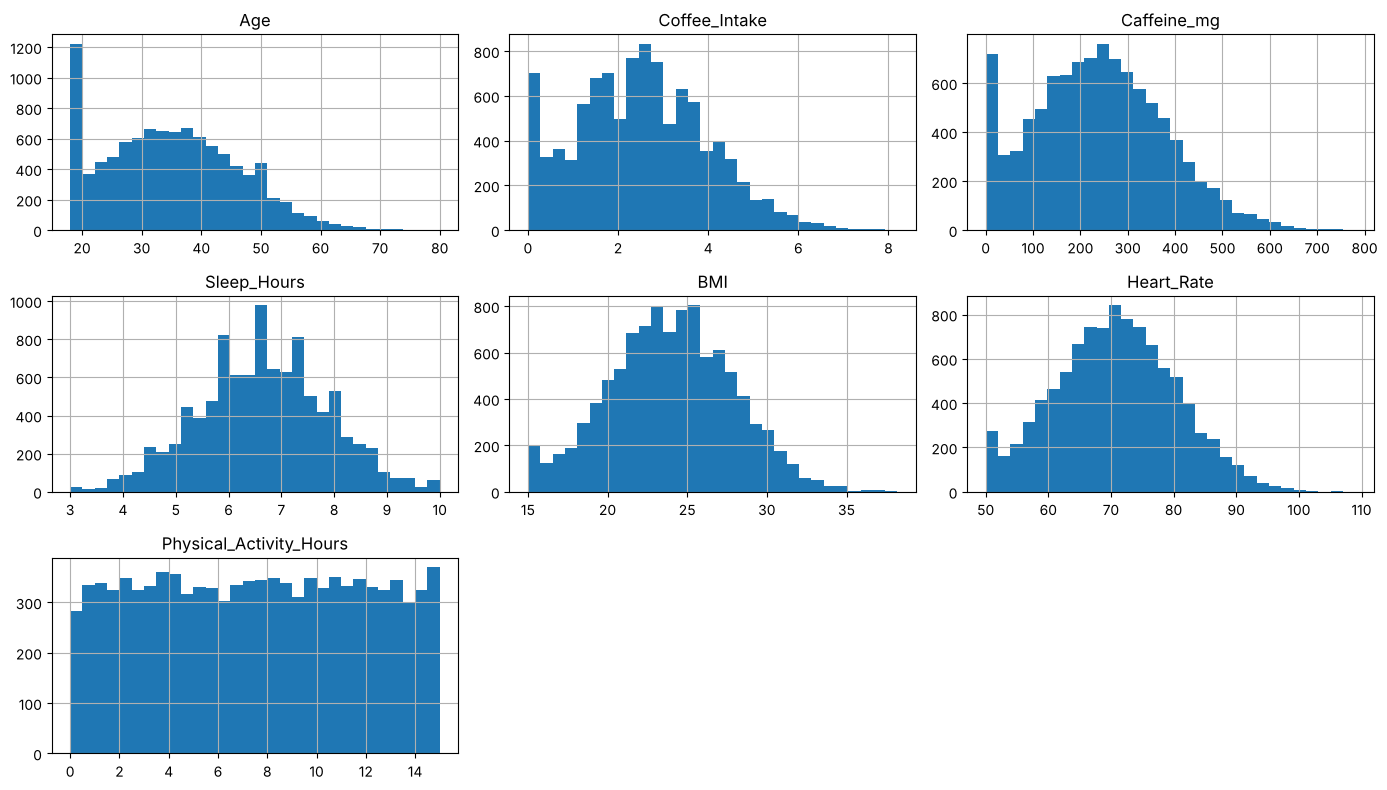

In [9]:
numericas = ["Age", "Coffee_Intake", "Caffeine_mg", "Sleep_Hours", "BMI", "Heart_Rate", "Physical_Activity_Hours"]

df[numericas].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

**Boxplots** — mostram a mediana, a dispersão e os valores fora do padrão (outliers, os pontinhos).

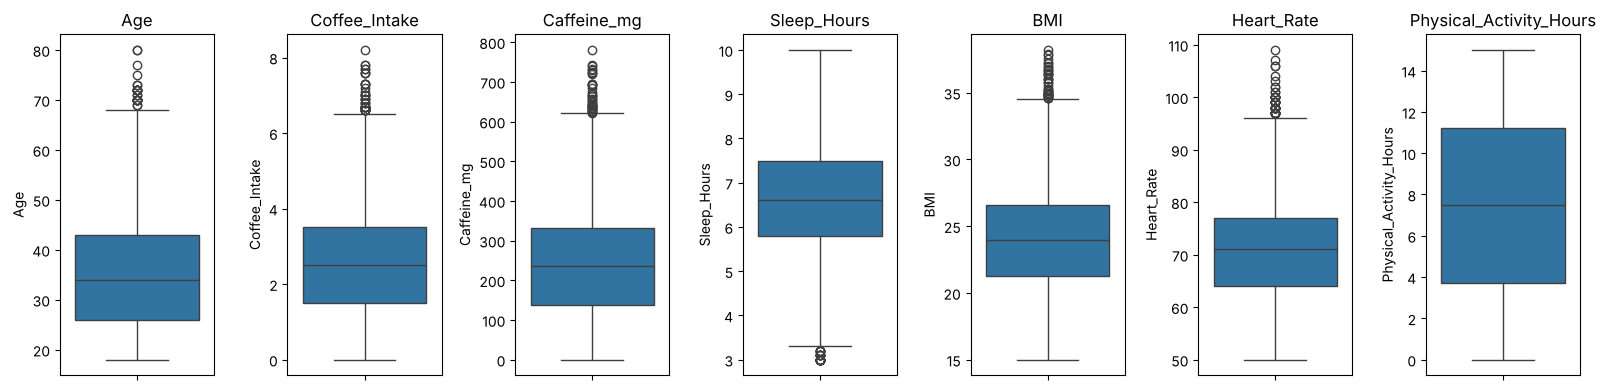

In [10]:
fig, axes = plt.subplots(1, 7, figsize=(16, 4))
for ax, coluna in zip(axes, numericas):
    sns.boxplot(y=df[coluna], ax=ax)
    ax.set_title(coluna)
plt.tight_layout()
plt.show()

## 3. Variáveis categóricas

**Gráficos de barras** — mostram quantas pessoas existem em cada categoria.

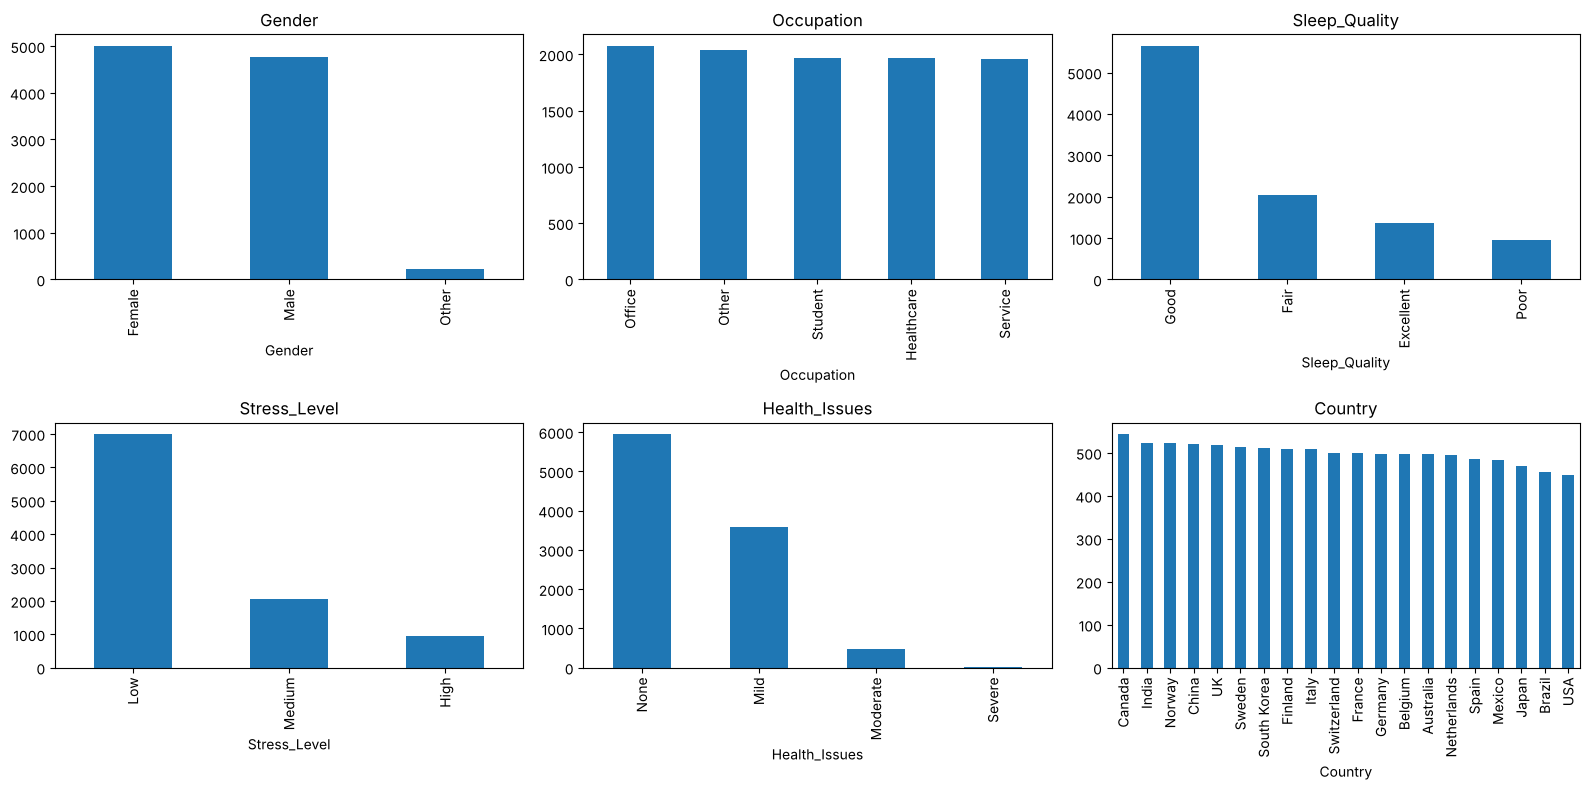

In [11]:
categoricas = ["Gender", "Occupation", "Sleep_Quality", "Stress_Level", "Health_Issues", "Country"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, coluna in zip(axes.flat, categoricas):
    df[coluna].value_counts().plot(kind="bar", ax=ax)
    ax.set_title(coluna)
plt.tight_layout()
plt.show()

**Gráficos de pizza** — mostram a proporção (%) de cada categoria.

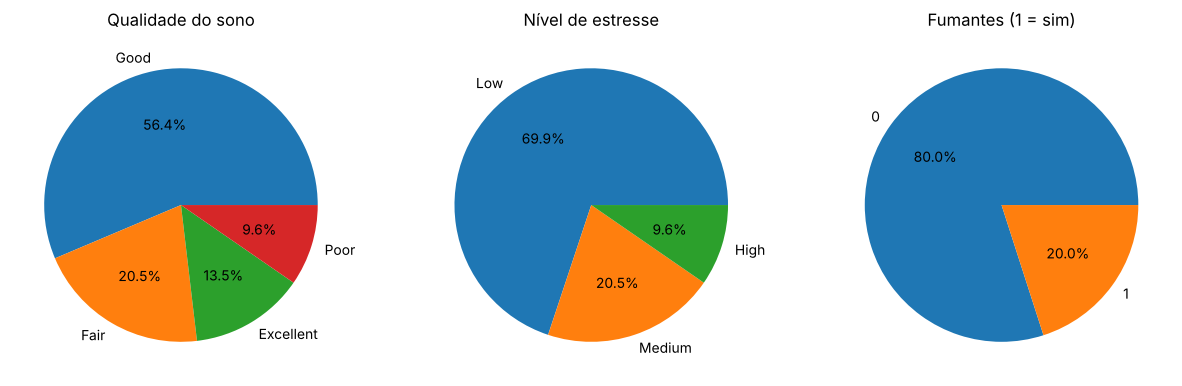

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
df["Sleep_Quality"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[0], title="Qualidade do sono")
df["Stress_Level"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[1], title="Nível de estresse")
df["Smoking"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[2], title="Fumantes (1 = sim)")
for ax in axes:
    ax.set_ylabel("")
plt.show()

## 4. Correlações

**Mapa de correlação** — mostra de −1 a 1 o quanto duas variáveis andam juntas (perto de 0 = nenhuma relação).

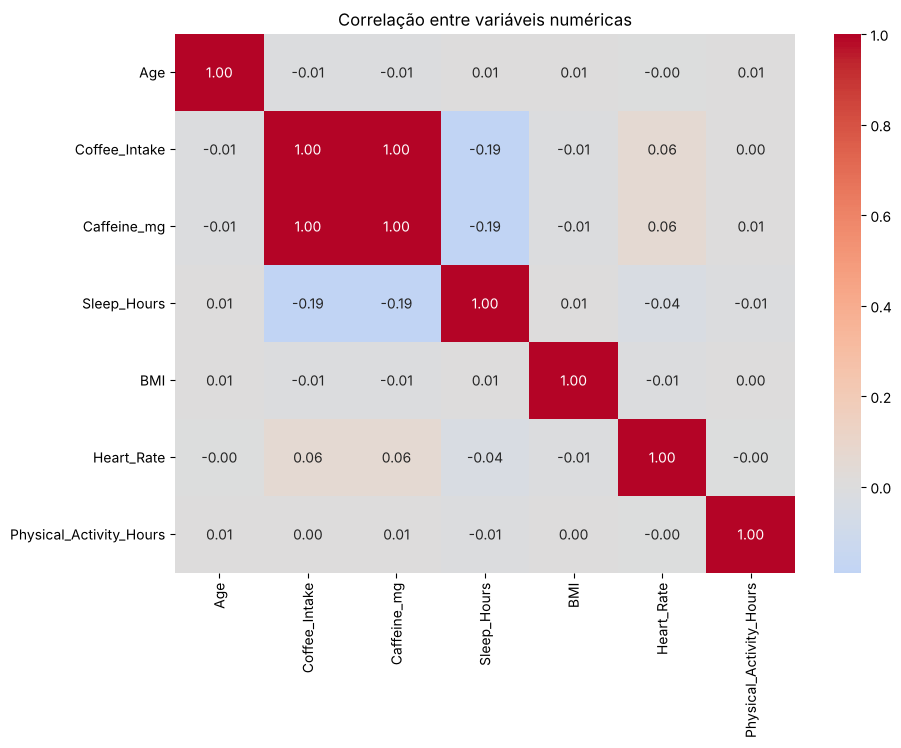

In [13]:
plt.figure(figsize=(10, 7))
sns.heatmap(df[numericas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação entre variáveis numéricas")
plt.show()

**Café × horas de sono** — cada ponto é uma pessoa; a linha vermelha mostra a tendência.

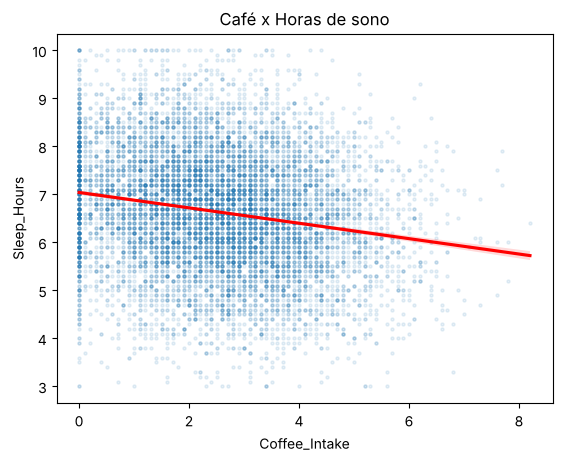

In [14]:
sns.regplot(data=df, x="Coffee_Intake", y="Sleep_Hours",
            scatter_kws={"alpha": 0.1, "s": 5}, line_kws={"color": "red"})
plt.title("Café x Horas de sono")
plt.show()

**Café × qualidade do sono** — compara o consumo de café em cada nível de qualidade do sono.

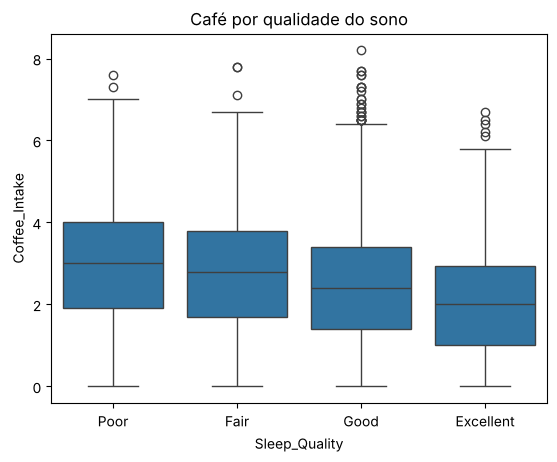

Sleep_Quality
Poor         2.979396
Fair         2.764049
Good         2.446780
Excellent    2.049038
Name: Coffee_Intake, dtype: float64

In [15]:
ordem_sono = ["Poor", "Fair", "Good", "Excellent"]
sns.boxplot(data=df, x="Sleep_Quality", y="Coffee_Intake", order=ordem_sono)
plt.title("Café por qualidade do sono")
plt.show()

df.groupby("Sleep_Quality")["Coffee_Intake"].mean().reindex(ordem_sono)

**Café × estresse** — compara o consumo de café em cada nível de estresse.

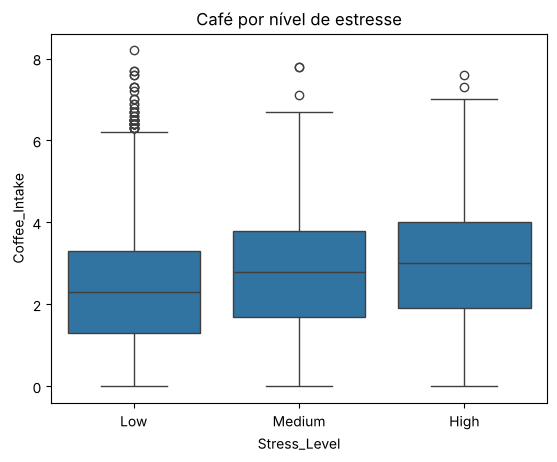

Stress_Level
Low       2.369838
Medium    2.764049
High      2.979396
Name: Coffee_Intake, dtype: float64

In [16]:
ordem_estresse = ["Low", "Medium", "High"]
sns.boxplot(data=df, x="Stress_Level", y="Coffee_Intake", order=ordem_estresse)
plt.title("Café por nível de estresse")
plt.show()

df.groupby("Stress_Level")["Coffee_Intake"].mean().reindex(ordem_estresse)

## 5. Principais achados

- **A base está limpa:** 10.000 pessoas, 16 colunas, sem duplicados. Os "nulos" de `Health_Issues` eram a categoria "None".
- **Perfil:** em média 35 anos, 2,5 xícaras de café por dia e 6,6 horas de sono por noite.
- **Mais café, menos sono:** a correlação entre café e horas de sono é negativa (−0,19). É uma relação fraca, mas aparece de forma clara.
- **Qualidade do sono:** quem dorme mal (*Poor*) toma em média 3,0 xícaras/dia; quem dorme muito bem (*Excellent*), 2,0.
- **Estresse:** quem tem estresse alto toma mais café (3,0 xícaras) do que quem tem estresse baixo (2,4).
- **Outras variáveis** (idade, IMC, atividade física, frequência cardíaca) quase não se relacionam com café ou sono.
- **Atenção:** `Caffeine_mg` é praticamente o número de xícaras × 95, então as duas colunas trazem a mesma informação.
- **Cuidado:** correlação não é causa — pode ser que quem dorme mal tome mais café para compensar o cansaço.

# 📊 Entrega 2 — Visualização e Insights

Agora que conhecemos a base, vamos comparar grupos e transformar os gráficos em **insights para o negócio**:
como o café, o estresse e outros fatores impactam o sono.

**Criar grupos** — para comparar clientes, separamos o consumo de café e a idade em faixas,
e marcamos quem tem **alto consumo de cafeína** (mais de 400 mg/dia, cerca de 4 xícaras — limite diário recomendado para adultos).

In [17]:
df["Faixa_Cafe"] = pd.cut(df["Coffee_Intake"], bins=[-1, 1, 3, 10],
                          labels=["Baixo (até 1)", "Moderado (1 a 3)", "Alto (mais de 3)"])
df["Faixa_Etaria"] = pd.cut(df["Age"], bins=[17, 29, 44, 59, 80],
                            labels=["18-29", "30-44", "45-59", "60+"])
df["Alta_Cafeina"] = df["Caffeine_mg"] > 400

ordem_sono = ["Poor", "Fair", "Good", "Excellent"]
ordem_estresse = ["Low", "Medium", "High"]

df[["Coffee_Intake", "Faixa_Cafe", "Age", "Faixa_Etaria", "Caffeine_mg", "Alta_Cafeina"]].head()

,Coffee_Intake,Faixa_Cafe,Age,Faixa_Etaria,Caffeine_mg,Alta_Cafeina
0,3.5,Alto (mais de 3),40,30-44,328.1,False
1,1.0,Baixo (até 1),33,30-44,94.1,False
2,5.3,Alto (mais de 3),42,30-44,503.7,True
3,2.6,Moderado (1 a 3),53,45-59,249.2,False
4,3.1,Alto (mais de 3),32,30-44,298.0,False


## 1. Gráficos comparativos

**Dispersão: cafeína × horas de sono, por estresse** — cada ponto é um cliente; a cor mostra o nível de estresse.

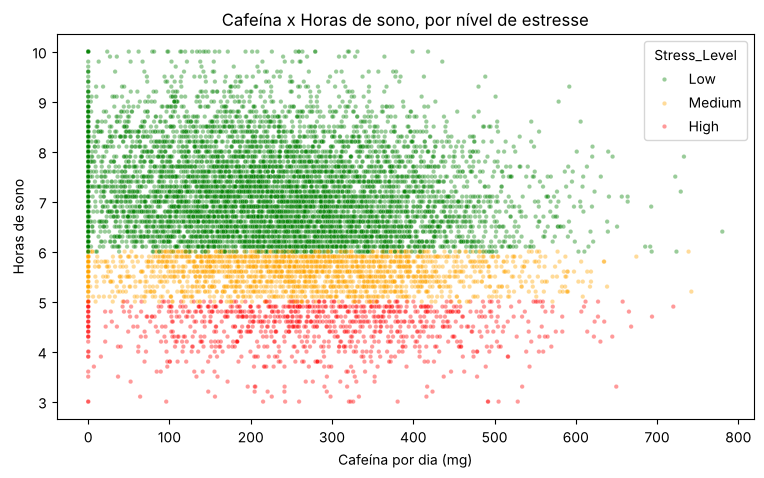

In [18]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Caffeine_mg", y="Sleep_Hours", hue="Stress_Level",
                hue_order=ordem_estresse, palette={"Low": "green", "Medium": "orange", "High": "red"},
                alpha=0.4, s=10)
plt.title("Cafeína x Horas de sono, por nível de estresse")
plt.xlabel("Cafeína por dia (mg)")
plt.ylabel("Horas de sono")
plt.show()

**Boxplot: horas de sono por faixa de café** — compara quanto dormem os clientes de cada faixa de consumo.

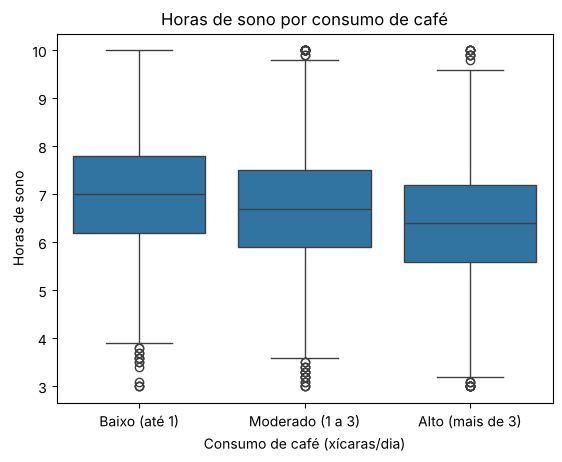

Faixa_Cafe
Baixo (até 1)       6.96
Moderado (1 a 3)    6.71
Alto (mais de 3)    6.38
Name: Sleep_Hours, dtype: float64

In [19]:
sns.boxplot(data=df, x="Faixa_Cafe", y="Sleep_Hours")
plt.title("Horas de sono por consumo de café")
plt.xlabel("Consumo de café (xícaras/dia)")
plt.ylabel("Horas de sono")
plt.show()

df.groupby("Faixa_Cafe")["Sleep_Hours"].mean().round(2)

**Barras empilhadas: qualidade do sono por faixa de café** — mostra a % de cada nível de qualidade dentro de cada faixa.

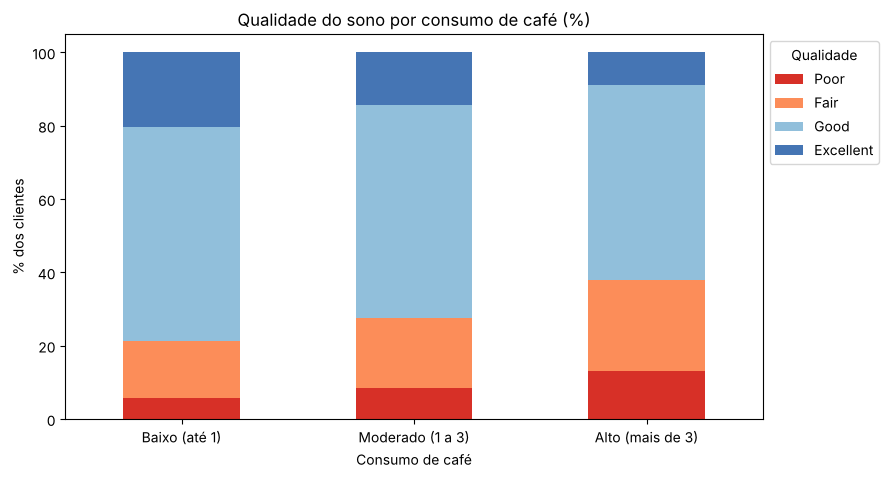

Sleep_Quality,Poor,Fair,Good,Excellent
Faixa_Cafe,,,,
Baixo (até 1),5.6,15.6,58.5,20.3
Moderado (1 a 3),8.5,19.1,58.0,14.4
Alto (mais de 3),13.0,24.8,53.1,9.0


In [20]:
qualidade_por_cafe = pd.crosstab(df["Faixa_Cafe"], df["Sleep_Quality"], normalize="index")[ordem_sono] * 100

qualidade_por_cafe.plot(kind="bar", stacked=True, figsize=(9, 5),
                        color=["#d73027", "#fc8d59", "#91bfdb", "#4575b4"])
plt.title("Qualidade do sono por consumo de café (%)")
plt.ylabel("% dos clientes")
plt.xlabel("Consumo de café")
plt.xticks(rotation=0)
plt.legend(title="Qualidade", bbox_to_anchor=(1, 1))
plt.show()

qualidade_por_cafe.round(1)

**Mapa de calor: média de sono por idade e café** — cores mais escuras = mais horas de sono.

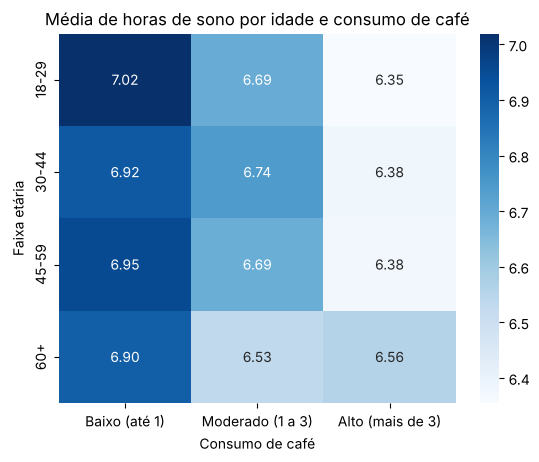

In [21]:
tabela = df.pivot_table(index="Faixa_Etaria", columns="Faixa_Cafe", values="Sleep_Hours", aggfunc="mean")

sns.heatmap(tabela, annot=True, fmt=".2f", cmap="Blues")
plt.title("Média de horas de sono por idade e consumo de café")
plt.xlabel("Consumo de café")
plt.ylabel("Faixa etária")
plt.show()

## 2. Análises segmentadas por grupos

### 2.1 Diferenças de sono por gênero

**Horas de sono por gênero** — boxplot e média de sono de cada gênero.

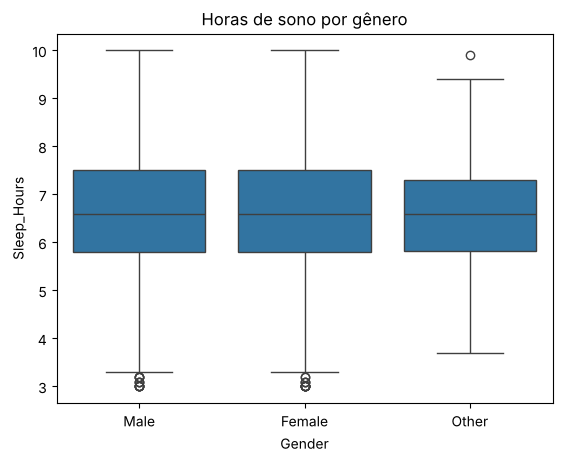

,mean,median,count
Gender,,,
Female,6.64,6.6,5001
Male,6.64,6.6,4773
Other,6.59,6.6,226


In [22]:
sns.boxplot(data=df, x="Gender", y="Sleep_Hours")
plt.title("Horas de sono por gênero")
plt.show()

df.groupby("Gender")["Sleep_Hours"].agg(["mean", "median", "count"]).round(2)

**Qualidade do sono por gênero** — % de cada nível de qualidade dentro de cada gênero.

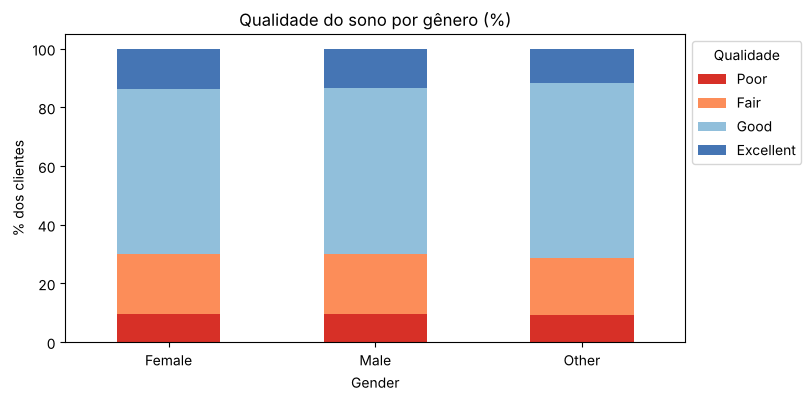

Sleep_Quality,Poor,Fair,Good,Excellent
Gender,,,,
Female,9.6,20.6,56.2,13.6
Male,9.6,20.5,56.4,13.5
Other,9.3,19.5,59.7,11.5


In [23]:
qualidade_por_genero = pd.crosstab(df["Gender"], df["Sleep_Quality"], normalize="index")[ordem_sono] * 100

qualidade_por_genero.plot(kind="bar", stacked=True, figsize=(8, 4),
                          color=["#d73027", "#fc8d59", "#91bfdb", "#4575b4"])
plt.title("Qualidade do sono por gênero (%)")
plt.ylabel("% dos clientes")
plt.xticks(rotation=0)
plt.legend(title="Qualidade", bbox_to_anchor=(1, 1))
plt.show()

qualidade_por_genero.round(1)

### 2.2 Idade e estresse em conjunto com o consumo de café

**Café por faixa etária e estresse** — média de xícaras por dia em cada combinação de idade e nível de estresse.

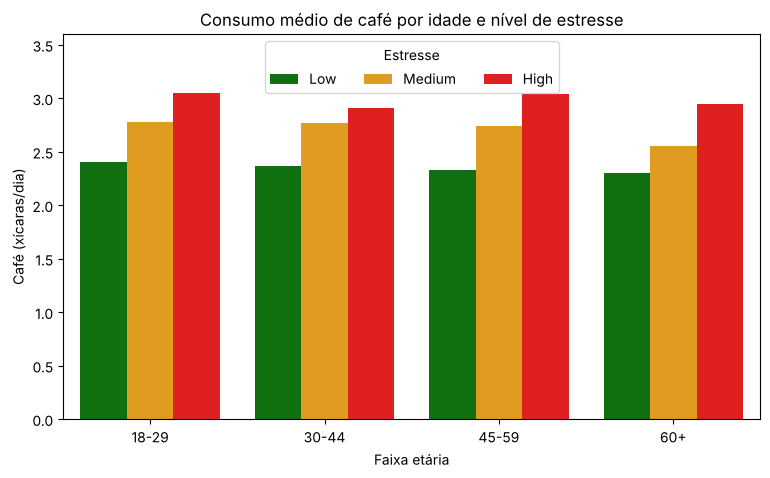

Stress_Level,Low,Medium,High
Faixa_Etaria,,,
18-29,2.40,2.78,3.05
30-44,2.36,2.77,2.91
45-59,2.33,2.74,3.04
60+,2.30,2.55,2.94


In [24]:
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="Faixa_Etaria", y="Coffee_Intake", hue="Stress_Level",
            hue_order=ordem_estresse, palette={"Low": "green", "Medium": "orange", "High": "red"},
            errorbar=None)
plt.title("Consumo médio de café por idade e nível de estresse")
plt.xlabel("Faixa etária")
plt.ylabel("Café (xícaras/dia)")
plt.ylim(0, 3.6)
plt.legend(title="Estresse", ncol=3, loc="upper center")
plt.show()

df.pivot_table(index="Faixa_Etaria", columns="Stress_Level", values="Coffee_Intake", aggfunc="mean")[ordem_estresse].round(2)

**Estresse × horas de sono** — quanto dormem, em média, os clientes de cada nível de estresse.

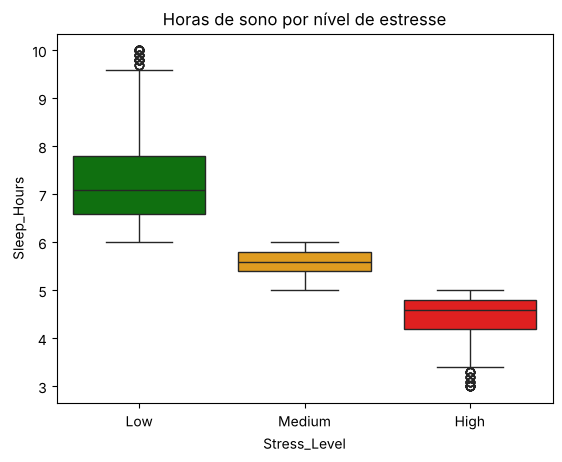

Sleep_Quality,Poor,Fair,Good,Excellent
Stress_Level,,,,
Low,0,0,5637,1352
Medium,0,2050,0,0
High,961,0,0,0


In [25]:
sns.boxplot(data=df, x="Stress_Level", y="Sleep_Hours", hue="Stress_Level", legend=False, order=ordem_estresse,
            palette={"Low": "green", "Medium": "orange", "High": "red"})
plt.title("Horas de sono por nível de estresse")
plt.show()

pd.crosstab(df["Stress_Level"], df["Sleep_Quality"]).loc[ordem_estresse, ordem_sono]

## 3. Insights de negócio

**Calcular os números dos insights** — o código calcula cada valor direto da base e escreve a frase pronta.

In [26]:
sono_alta = df.loc[df["Alta_Cafeina"], "Sleep_Hours"].mean()
sono_normal = df.loc[~df["Alta_Cafeina"], "Sleep_Hours"].mean()
dif = sono_normal - sono_alta
print(f"1. Clientes com alto consumo de cafeína (> 400 mg/dia) dormem em média {dif:.2f} h "
      f"(~{dif * 60:.0f} min) a menos: {sono_alta:.2f} h contra {sono_normal:.2f} h.")
print(f"   Eles são {df['Alta_Cafeina'].mean() * 100:.1f}% dos clientes.")

poor_baixo = qualidade_por_cafe.loc["Baixo (até 1)", "Poor"]
poor_alto = qualidade_por_cafe.loc["Alto (mais de 3)", "Poor"]
print(f"2. O sono ruim (Poor) passa de {poor_baixo:.1f}% entre quem toma até 1 xícara "
      f"para {poor_alto:.1f}% entre quem toma mais de 3 — {poor_alto / poor_baixo:.1f}x mais.")

sono_estresse = df.groupby("Stress_Level")["Sleep_Hours"].mean()
print(f"3. Clientes com estresse alto dormem {sono_estresse['Low'] - sono_estresse['High']:.1f} h a menos "
      f"que os de estresse baixo ({sono_estresse['High']:.2f} h x {sono_estresse['Low']:.2f} h), "
      f"e 100% deles têm sono Poor.")

cafe_estresse = df.groupby("Stress_Level")["Coffee_Intake"].mean()
print(f"4. Quem tem estresse alto toma {cafe_estresse['High']:.2f} xícaras/dia, contra {cafe_estresse['Low']:.2f} "
      f"no estresse baixo — {(cafe_estresse['High'] / cafe_estresse['Low'] - 1) * 100:.0f}% a mais. "
      f"Esse padrão se repete em todas as faixas etárias.")

sono_genero = df.groupby("Gender")["Sleep_Hours"].mean()
print(f"5. Gênero não muda o sono: média de {sono_genero.min():.2f} a {sono_genero.max():.2f} h entre os grupos.")

1. Clientes com alto consumo de cafeína (> 400 mg/dia) dormem em média 0.45 h (~27 min) a menos: 6.24 h contra 6.69 h.
   Eles são 12.5% dos clientes.
2. O sono ruim (Poor) passa de 5.6% entre quem toma até 1 xícara para 13.0% entre quem toma mais de 3 — 2.3x mais.
3. Clientes com estresse alto dormem 2.8 h a menos que os de estresse baixo (4.45 h x 7.25 h), e 100% deles têm sono Poor.
4. Quem tem estresse alto toma 2.98 xícaras/dia, contra 2.37 no estresse baixo — 26% a mais. Esse padrão se repete em todas as faixas etárias.
5. Gênero não muda o sono: média de 6.59 a 6.64 h entre os grupos.


## 4. Principais Descobertas

1. **Café alto = menos sono.** Clientes com mais de 400 mg de cafeína por dia dormem cerca de **27 minutos a menos** por noite (6,24 h × 6,69 h). Eles são 12,5% da base.
2. **Mais café, pior qualidade de sono.** O sono *Poor* vai de **5,6%** (até 1 xícara) para **13%** (mais de 3 xícaras), e o *Excellent* cai de 20% para 9%.
3. **O estresse é o fator que mais pesa no sono.** Estresse alto = **2,8 h a menos** de sono que estresse baixo (4,45 h × 7,25 h), e todos os clientes com estresse alto têm sono *Poor*.
4. **Estresse e café andam juntos.** Clientes estressados tomam cerca de **26% mais café** (2,98 × 2,37 xícaras/dia), em todas as idades.
5. **Gênero e idade quase não fazem diferença.** O sono médio é praticamente igual entre homens, mulheres e outros (~6,6 h) e entre as faixas etárias; o efeito do café aparece em todas as idades.

**Para o negócio:** campanhas de bem-estar podem focar em clientes com **alto consumo de café e estresse elevado**, o grupo com pior sono — por exemplo, sugerindo opções descafeinadas no fim do dia.

> Lembrete: estas são associações, não causa e efeito. Pode ser que quem dorme mal tome mais café para compensar o cansaço.

**Painel das descobertas** — os quatro gráficos que resumem os principais achados, lado a lado.

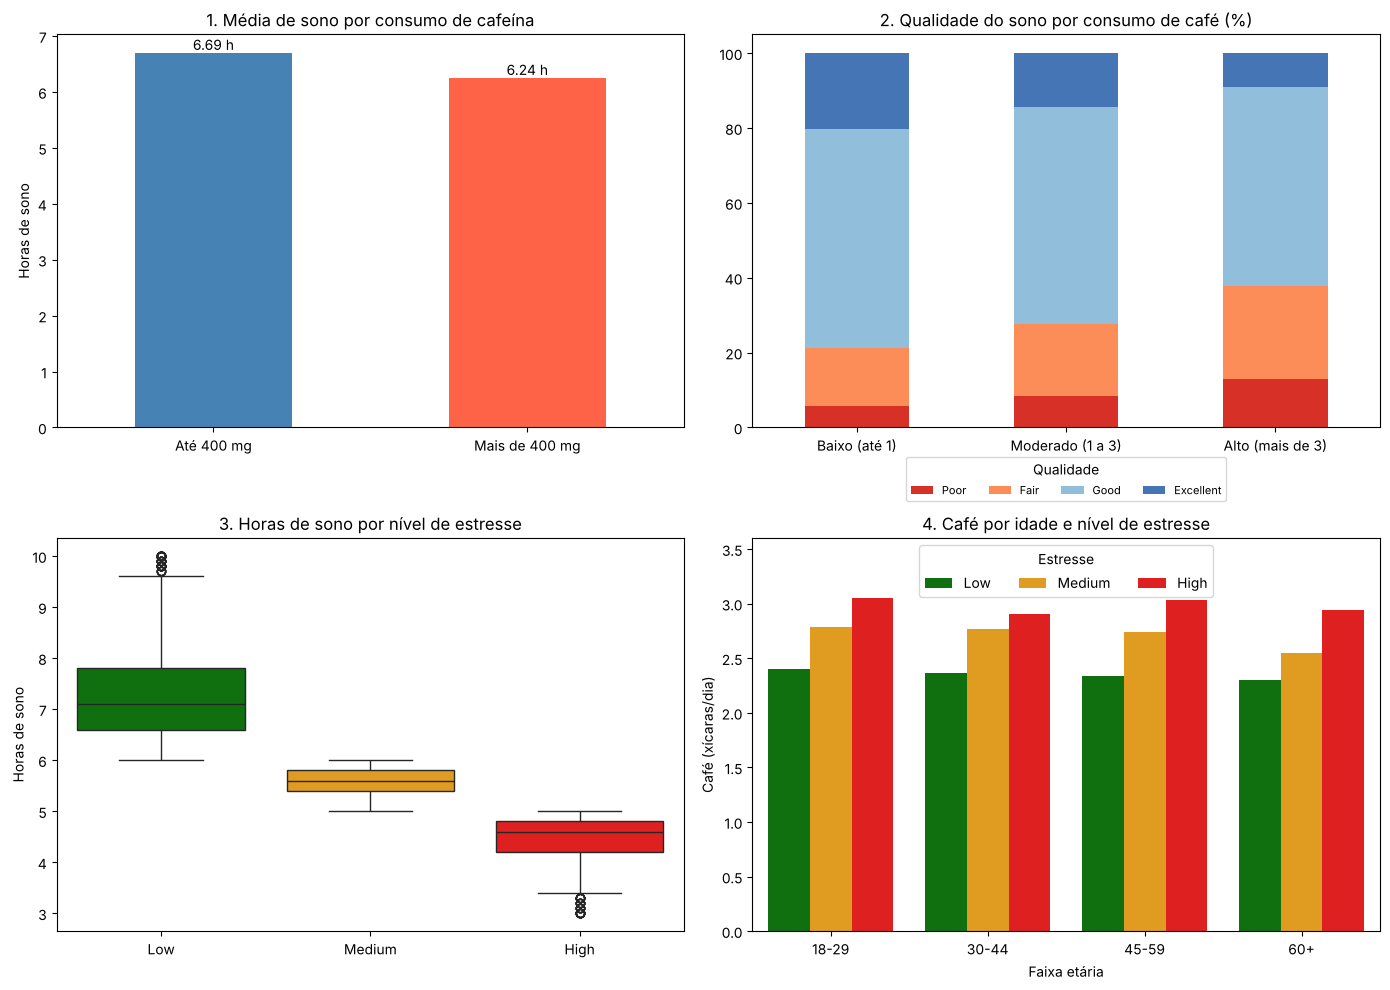

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

df.groupby("Alta_Cafeina")["Sleep_Hours"].mean().rename({False: "Até 400 mg", True: "Mais de 400 mg"}).plot(
    kind="bar", ax=axes[0, 0], color=["steelblue", "tomato"])
axes[0, 0].set_title("1. Média de sono por consumo de cafeína")
axes[0, 0].set_ylabel("Horas de sono")
axes[0, 0].set_xlabel("")
axes[0, 0].tick_params(axis="x", rotation=0)
axes[0, 0].bar_label(axes[0, 0].containers[0], fmt="%.2f h")

qualidade_por_cafe.plot(kind="bar", stacked=True, ax=axes[0, 1],
                        color=["#d73027", "#fc8d59", "#91bfdb", "#4575b4"])
axes[0, 1].set_title("2. Qualidade do sono por consumo de café (%)")
axes[0, 1].set_xlabel("")
axes[0, 1].tick_params(axis="x", rotation=0)
axes[0, 1].legend(title="Qualidade", fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.06))

sns.boxplot(data=df, x="Stress_Level", y="Sleep_Hours", hue="Stress_Level", legend=False, order=ordem_estresse, ax=axes[1, 0],
            palette={"Low": "green", "Medium": "orange", "High": "red"})
axes[1, 0].set_title("3. Horas de sono por nível de estresse")
axes[1, 0].set_ylabel("Horas de sono")
axes[1, 0].set_xlabel("")

sns.barplot(data=df, x="Faixa_Etaria", y="Coffee_Intake", hue="Stress_Level", hue_order=ordem_estresse,
            palette={"Low": "green", "Medium": "orange", "High": "red"}, errorbar=None, ax=axes[1, 1])
axes[1, 1].set_title("4. Café por idade e nível de estresse")
axes[1, 1].set_ylabel("Café (xícaras/dia)")
axes[1, 1].set_xlabel("Faixa etária")
axes[1, 1].set_ylim(0, 3.6)
axes[1, 1].legend(title="Estresse", ncol=3, loc="upper center")

plt.tight_layout()
plt.show()

# 🤖 Entrega 3 — Modelo preditivo

Objetivo: prever a **qualidade do sono** (`Sleep_Quality`: Poor, Fair, Good ou Excellent) a partir dos hábitos e características dos clientes.

**Importar as ferramentas de machine learning** — trazemos do scikit-learn as funções para dividir os dados, treinar e avaliar os modelos, e o `joblib` para salvar o modelo.

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import joblib

## 1. Pré-processamento dos dados

**Copiar a base e criar a feature derivada** — trabalhamos numa cópia e criamos `Alta_Cafeina` (1 = mais de 400 mg de cafeína por dia, 0 = até 400 mg).

In [29]:
dados = df.copy()
dados["Alta_Cafeina"] = (dados["Caffeine_mg"] > 400).astype(int)
dados["Alta_Cafeina"].value_counts()

Alta_Cafeina
0    8754
1    1246
Name: count, dtype: int64

**Remover colunas irrelevantes** — tiramos as colunas que não ajudam ou que atrapalhariam o modelo:

- `ID`: é só um número de identificação.
- `Caffeine_mg`: repete a mesma informação de `Coffee_Intake` (xícaras × 95).
- `Country`: não mostrou relação com o sono na análise.
- `Stress_Level` e `Health_Issues`: na Entrega 1 vimos que elas são **calculadas a partir das horas de sono**. Usá-las seria "dar a resposta" ao modelo (vazamento de dados).
- `Faixa_Cafe` e `Faixa_Etaria`: colunas auxiliares que criamos só para os gráficos da Entrega 2.

In [30]:
dados = dados.drop(columns=["ID", "Caffeine_mg", "Country", "Stress_Level", "Health_Issues",
                            "Faixa_Cafe", "Faixa_Etaria"], errors="ignore")
dados.columns.tolist()

['Age',
 'Gender',
 'Coffee_Intake',
 'Sleep_Hours',
 'Sleep_Quality',
 'BMI',
 'Heart_Rate',
 'Physical_Activity_Hours',
 'Occupation',
 'Smoking',
 'Alcohol_Consumption',
 'Alta_Cafeina']

**Codificar as variáveis categóricas** — o modelo só entende números, então transformamos `Gender` e `Occupation` em colunas de 0 e 1 (*one-hot encoding*).

In [31]:
dados = pd.get_dummies(dados, columns=["Gender", "Occupation"], drop_first=True, dtype=int)
dados.head()

,Age,Coffee_Intake,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Physical_Activity_Hours,Smoking,Alcohol_Consumption,Alta_Cafeina,Gender_Male,Gender_Other,Occupation_Office,Occupation_Other,Occupation_Service,Occupation_Student
0,40,3.5,7.5,Good,24.9,78,14.5,0,0,0,1,0,0,1,0,0
1,33,1.0,6.2,Good,20.0,67,11.0,0,0,0,1,0,0,0,1,0
2,42,5.3,5.9,Fair,22.7,59,11.2,0,0,1,1,0,1,0,0,0
3,53,2.6,7.3,Good,24.7,71,6.6,0,0,0,1,0,0,1,0,0
4,32,3.1,5.3,Fair,24.1,76,8.5,0,1,0,0,0,0,0,0,1


**Separar entradas (X) e alvo (y)** — `X` são as informações do cliente; `y` é o que queremos prever, a qualidade do sono.

In [32]:
X = dados.drop(columns="Sleep_Quality")
y = dados["Sleep_Quality"]

print("Variáveis usadas pelo modelo:", X.columns.tolist())

Variáveis usadas pelo modelo: ['Age', 'Coffee_Intake', 'Sleep_Hours', 'BMI', 'Heart_Rate', 'Physical_Activity_Hours', 'Smoking', 'Alcohol_Consumption', 'Alta_Cafeina', 'Gender_Male', 'Gender_Other', 'Occupation_Office', 'Occupation_Other', 'Occupation_Service', 'Occupation_Student']


## 2. Dividir em treino e teste

**Treino e teste** — 80% dos clientes servem para o modelo aprender e 20% ficam guardados para testar se ele acerta em dados que nunca viu. O `stratify` mantém a mesma proporção de cada classe nos dois grupos.

In [33]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Treino:", X_treino.shape[0], "clientes")
print("Teste: ", X_teste.shape[0], "clientes")

Treino: 8000 clientes
Teste:  2000 clientes


## 3. Treinar e comparar os modelos

**Modelo 1 — Regressão Logística** — um modelo simples que aprende uma "fórmula" para separar as classes. Antes, os números são colocados na mesma escala (`StandardScaler`).

In [34]:
modelo_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modelo_lr.fit(X_treino, y_treino)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['Excellent','Fair','Good','Poor']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['Age','Coffee_Intake','Sleep_Hours',...,'Occupation_Other', 'Occupation_Service','Occupation_Student']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


**Modelo 2 — Random Forest** — combina centenas de árvores de decisão e decide pela "votação" entre elas.

In [35]:
modelo_rf = RandomForestClassifier(random_state=42)
modelo_rf.fit(X_treino, y_treino)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

**Acurácia no treino e no teste** — % de acertos de cada modelo. Comparar treino × teste mostra se o modelo decorou os dados (overfitting).

In [36]:
modelos = {"Regressão Logística": modelo_lr, "Random Forest": modelo_rf}

resultados = pd.DataFrame({
    nome: {"Acurácia treino": accuracy_score(y_treino, m.predict(X_treino)),
           "Acurácia teste": accuracy_score(y_teste, m.predict(X_teste))}
    for nome, m in modelos.items()
}).T
resultados["Diferença"] = resultados["Acurácia treino"] - resultados["Acurácia teste"]
resultados.round(3)

,Acurácia treino,Acurácia teste,Diferença
Regressão Logística,0.975,0.970,0.005
Random Forest,1.000,0.968,0.032


**Relatório de classificação** — mostra, para cada classe, a precisão (quando o modelo diz "Poor", quantas vezes acerta) e o recall (dos clientes realmente "Poor", quantos ele encontra).

In [37]:
ordem_sono = ["Poor", "Fair", "Good", "Excellent"]
for nome, m in modelos.items():
    print("=" * 20, nome, "=" * 20)
    print(classification_report(y_teste, m.predict(X_teste), labels=ordem_sono))

==================== Regressão Logística ====================
              precision    recall  f1-score   support

        Poor       0.98      0.97      0.98       192
        Fair       0.97      0.92      0.95       410
        Good       0.97      0.99      0.98      1128
   Excellent       0.97      0.96      0.96       270

    accuracy                           0.97      2000
   macro avg       0.97      0.96      0.97      2000
weighted avg       0.97      0.97      0.97      2000

==================== Random Forest ====================
              precision    recall  f1-score   support

        Poor       0.96      0.97      0.97       192
        Fair       0.98      0.90      0.94       410
        Good       0.96      0.99      0.98      1128
   Excellent       0.99      0.95      0.97       270

    accuracy                           0.97      2000
   macro avg       0.97      0.95      0.96      2000
weighted avg       0.97      0.97      0.97      2000



**Matriz de confusão** — a diagonal são os acertos; fora dela, os erros (ex.: clientes *Fair* que o modelo previu como *Good*).

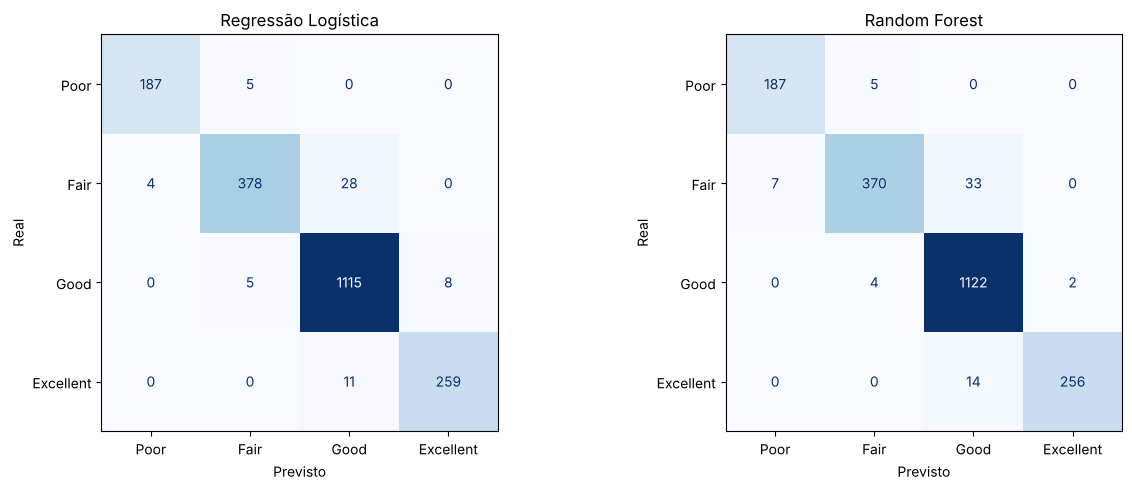

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (nome, m) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_teste, y_teste, labels=ordem_sono, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(nome)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

**Importância das variáveis** — o Random Forest mostra quanto cada variável pesou nas decisões.

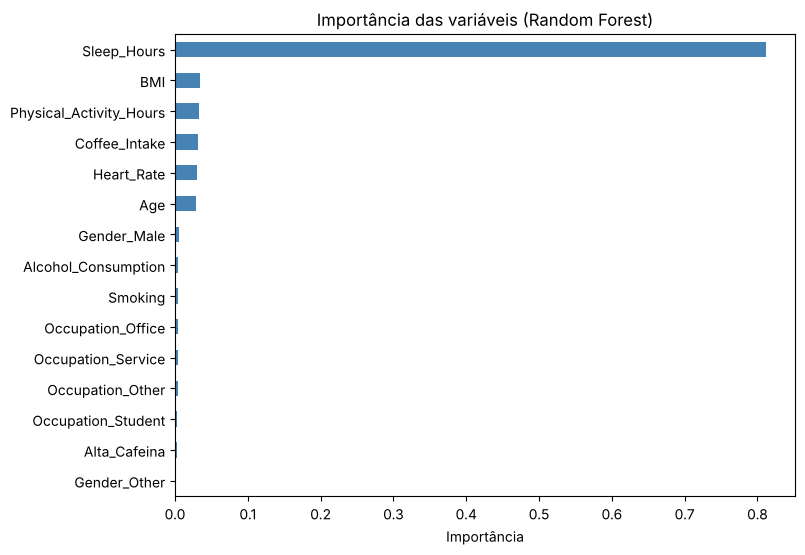

Sleep_Hours                0.811
BMI                        0.034
Physical_Activity_Hours    0.033
Coffee_Intake              0.031
Heart_Rate                 0.030
Age                        0.029
dtype: float64

In [39]:
importancia = pd.Series(modelo_rf.feature_importances_, index=X.columns).sort_values()
importancia.plot(kind="barh", figsize=(8, 6), color="steelblue")
plt.title("Importância das variáveis (Random Forest)")
plt.xlabel("Importância")
plt.show()

importancia.sort_values(ascending=False).head(6).round(3)

**Teste extra: e sem as horas de sono?** — treinamos de novo sem `Sleep_Hours` para ver se café, idade e os outros hábitos conseguem prever o sono sozinhos. Comparamos com um "chute" que sempre diz *Good* (a classe mais comum).

In [40]:
modelo_sem_sono = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modelo_sem_sono.fit(X_treino.drop(columns="Sleep_Hours"), y_treino)

acc_sem_sono = accuracy_score(y_teste, modelo_sem_sono.predict(X_teste.drop(columns="Sleep_Hours")))
acc_chute = (y_teste == "Good").mean()
print(f"Acurácia sem horas de sono:  {acc_sem_sono:.1%}")
print(f"Acurácia chutando sempre 'Good': {acc_chute:.1%}")

Acurácia sem horas de sono:  56.4%
Acurácia chutando sempre 'Good': 56.4%


## 4. Avaliação dos modelos

**Qual modelo performou melhor?**
Os dois acertam cerca de **97%** dos clientes de teste. A **Regressão Logística** ficou um pouco à frente (~97,0% contra ~96,8%) e é mais simples, então é o modelo escolhido.
Os erros acontecem quase sempre entre classes **vizinhas** (ex.: *Fair* × *Good*), que são os clientes com horas de sono perto do limite entre as faixas.

**Há overfitting ou underfitting?**
- **Regressão Logística:** **não há overfitting** — a acurácia no treino (~97,5%) e no teste (~97,0%) é praticamente igual.
- **Random Forest:** **leve overfitting** — acerta 100% no treino, mas ~96,8% no teste: ele "decorou" parte dos dados de treino.
- **Sem as horas de sono:** o modelo cai para ~56%, o mesmo que chutar sempre *Good*. Isso é **underfitting**: café, idade, IMC e os outros hábitos sozinhos não trazem informação suficiente.

**Ponto de atenção:** o que mais explica a qualidade do sono são as **horas de sono** (~80% da importância). Nesta base (sintética), a qualidade do sono é praticamente definida pelas horas dormidas — por isso a acurácia é tão alta. O café influencia a qualidade **indiretamente**: quem toma mais café dorme menos horas (Entrega 2).

## 5. Salvar o dataset processado

**Salvar em CSV** — guardamos a base já tratada e codificada, pronta para ser usada de novo. O arquivo fica na pasta `data/`.

In [41]:
dados.to_csv("data/coffee_health_processado.csv", index=False)
print("Dataset salvo:", dados.shape[0], "linhas e", dados.shape[1], "colunas")

Dataset salvo: 10000 linhas e 16 colunas


## 6. Salvar o melhor modelo

**Escolher e salvar o melhor modelo** — o código pega o modelo com maior acurácia no teste e salva em um arquivo `.pkl` na pasta `modelo/`, que pode ser carregado depois sem treinar de novo.

In [42]:
nome_melhor = resultados["Acurácia teste"].idxmax()
melhor_modelo = modelos[nome_melhor]

joblib.dump(melhor_modelo, "modelo/modelo_qualidade_sono.pkl")
print("Melhor modelo:", nome_melhor, f"({resultados.loc[nome_melhor, 'Acurácia teste']:.1%} de acurácia no teste)")
print("Salvo em: modelo/modelo_qualidade_sono.pkl")

Melhor modelo: Regressão Logística (97.0% de acurácia no teste)
Salvo em: modelo/modelo_qualidade_sono.pkl


**Testar o modelo salvo** — carregamos o arquivo e prevemos a qualidade do sono de um cliente de exemplo.

In [43]:
modelo_carregado = joblib.load("modelo/modelo_qualidade_sono.pkl")

cliente = X_teste.iloc[[0]]
print("Previsão:", modelo_carregado.predict(cliente)[0], "| Real:", y_teste.iloc[0])
cliente

Previsão: Fair | Real: Fair


,Age,Coffee_Intake,Sleep_Hours,BMI,Heart_Rate,Physical_Activity_Hours,Smoking,Alcohol_Consumption,Alta_Cafeina,Gender_Male,Gender_Other,Occupation_Office,Occupation_Other,Occupation_Service,Occupation_Student
4695,32,5.6,5.9,19.2,63,4.6,0,1,1,1,0,0,0,0,0


## 7. Recomendações para o Negócio

1. **Usar o modelo para identificar clientes com risco de sono ruim.** Com poucas informações (horas de sono, consumo de café e perfil), o modelo classifica a qualidade do sono com ~97% de acerto. A empresa pode usar isso num questionário rápido do app ou site para encontrar quem precisa de orientação.
2. **Orientar sobre o limite de cafeína.** Clientes com mais de 400 mg por dia (~4 xícaras) dormem em média 27 minutos a menos. Uma recomendação clara é **ficar abaixo de 3–4 xícaras por dia**.
3. **Evitar café perto da hora de dormir.** Como o café afeta o sono pela **redução das horas dormidas**, a empresa pode sugerir um "horário limite" para o café (ex.: até o meio da tarde) e oferecer **opções descafeinadas** à noite.
4. **Dar atenção especial a clientes estressados.** Eles tomam ~26% mais café e são os que menos dormem. Programas de bem-estar (pausas, meditação, rotina de sono) podem ser direcionados a esse grupo.
5. **Personalizar sem segmentar por gênero ou idade.** Esses fatores quase não mudaram o sono; as recomendações devem se basear nos **hábitos** de cada cliente.
6. **Próximo passo:** coletar dados reais (horário do último café, uso de telas, rotina) para que o modelo consiga prever o sono **antes** de o cliente informar quantas horas dorme.